# Exploratory Data Analysis of the Manchester Housing Market
**Module:** COM7024 Programming for Data Analytics | **Student ID:** 25350515

This workbook examines data on residential property sales provided by Estate Management Plc.
The Manager requested that I investigate three areas of interest:
1. Waterfront properties
2. Floor area
3. Whether the age of the property (i.e., the year it was constructed) has an impact on its sale price.

To complete each of these requests, I will follow all of the guidelines for investigation as stated in the Brief: load the data into Python using pandas, determine the type of data, create some basic statistics, clean-up/transform the data, generate the statistics once more, and finally use graphics to examine each question.

## Section 1 - Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pandas is used as the default library to handle table data in Python and is used alongside seaborn due to how much easier it is to make visually appealing plots using fewer lines of code than matplotlib. Only the libraries are imported here, and each chart is displayed with `plt.show()`, which keeps the code short and easy to follow.

## Section 2 - Import dataset

In [2]:
import pandas as pd              
import numpy as np               
import matplotlib.pyplot as plt        
from scipy import stats           
import seaborn as sns   

# utf-8-sig removes a hidden character at the start of the file
RAW_FILE = "Manchester_house_Dataset[3678].csv"
raw = pd.read_csv(RAW_FILE, encoding="utf-8-sig")

print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (19999, 15)


,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_total,floors,waterfront,view,condition,grade,built,renovated,living_area
0,0,7129300520,221900,3.0,1.00,1180,5650,1.0,0,0,3,7,1955,0,1340
1,1,6414100192,538000,3.0,2.25,2570,7242,2.0,0,0,3,7,1951,1991,1690
2,2,5631500400,180000,2.0,1.00,770,10000,1.0,0,0,3,6,1933,0,2720
3,3,2487200875,604000,4.0,3.00,1960,5000,1.0,0,0,5,7,1965,0,1360
4,4,1954400510,510000,3.0,2.00,1680,8080,1.0,0,0,3,8,1987,0,1800


The file contained 19,999 rows and 15 columns. To begin the process, I had to deal with a problem in the first column name that initially seemed wrong; it was found that this was due to a 'hidden' character at the beginning of the file. Therefore, I added an encoding parameter when loading the file. Upon reviewing the first few rows I realised that neither sale date nor property address were available. Therefore, I will be unable to analyse sales locations or identify changes over time.

## Section  3 - Check the data types

In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19999 entries, 0 to 19998
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   19999 non-null  int64  
 1   id           19999 non-null  int64  
 2   price        19999 non-null  int64  
 3   bedrooms     19986 non-null  float64
 4   bathrooms    19989 non-null  float64
 5   sqft_living  19999 non-null  int64  
 6   sqft_total   19999 non-null  int64  
 7   floors       19999 non-null  float64
 8   waterfront   19999 non-null  int64  
 9   view         19999 non-null  int64  
 10  condition    19999 non-null  int64  
 11  grade        19999 non-null  int64  
 12  built        19999 non-null  int64  
 13  renovated    19999 non-null  int64  
 14  living_area  19999 non-null  int64  
dtypes: float64(3), int64(12)
memory usage: 2.3 MB


In [4]:
# the type each column should really be
expected = {
    "Unnamed: 0": "redundant row index -> drop",
    "id": "identifier -> string (not a quantity)",
    "price": "int (GBP)",
    "bedrooms": "int (count)",
    "bathrooms": "float (half-baths exist)",
    "sqft_living": "int",
    "sqft_total": "int",
    "floors": "float (1.5 floors exist)",
    "waterfront": "category / boolean (0/1)",
    "view": "ordinal category 0-4",
    "condition": "ordinal category 1-5",
    "grade": "ordinal category 1-13",
    "built": "int (year)",
    "renovated": "int (year, 0 = never)",
    "living_area": "int",
}
dtype_check = pd.DataFrame({"pandas_dtype": raw.dtypes.astype(str),
                            "expected_type": pd.Series(expected)})
dtype_check

,pandas_dtype,expected_type
Unnamed: 0,int64,redundant row index -> drop
id,int64,identifier -> string (not a quantity)
price,int64,int (GBP)
bedrooms,float64,int (count)
bathrooms,float64,float (half-baths exist)
sqft_living,int64,int
sqft_total,int64,int
floors,float64,float (1.5 floors exist)
waterfront,int64,category / boolean (0/1)
view,int64,ordinal category 0-4


Everything was read into numbers. That doesn't mean they're the correct type for each column. `id` is a label and you wouldn't want to sum it. The fact `bedrooms` is a float is due to there being some missing values. `waterfront`, `view`, `condition`, and `grade` were always categorical. This step allowed me to come up with an idea of how I could clean my data in the next steps before actually doing so.

## Section 4 - Basic statistics on all variables (before cleaning)

In [5]:
initial_stats = raw.describe().T
initial_stats["skew"] = raw.skew(numeric_only=True)
initial_stats["missing"] = raw.isna().sum()
initial_stats.style.format("{:,.2f}")   # 2 decimals instead of scientific notation

,count,mean,std,min,25%,50%,75%,max,skew,missing
Unnamed: 0,"19,999.00","9,999.00","5,773.36",0.00,"4,999.50","9,999.00","14,998.50","19,998.00",0.00,0.00
id,"19,999.00","4,569,211,712.19","2,866,327,005.36","1,000,102.00","2,123,049,158.50","3,905,080,310.00","7,300,300,305.00","9,900,000,190.00",0.25,0.00
price,"19,999.00","535,468.02","365,956.63","75,000.00","317,000.00","449,950.00","640,000.00","7,700,000.00",4.12,0.00
bedrooms,"19,986.00",3.37,0.93,1.00,3.00,3.00,4.00,33.00,2.15,13.00
bathrooms,"19,989.00",2.07,0.76,0.50,1.50,2.00,2.50,8.00,0.55,10.00
sqft_living,"19,999.00","2,057.89",905.64,290.00,"1,420.00","1,900.00","2,510.00","13,540.00",1.52,0.00
sqft_total,"19,999.00","15,607.00","41,771.19",520.00,"5,350.00","7,819.00","11,000.00","1,651,359.00",13.04,0.00
floors,"19,999.00",1.44,0.52,1.00,1.00,1.00,2.00,3.50,0.68,0.00
waterfront,"19,999.00",0.01,0.09,0.00,0.00,0.00,0.00,1.00,11.08,0.00
view,"19,999.00",0.24,0.78,0.00,0.00,0.00,0.00,4.00,3.33,0.00


In [6]:
# Missing values and duplicates
missing_before = raw.isna().sum()
print("Missing values per column:\n", missing_before[missing_before > 0])
print("\nTotal missing cells:", int(missing_before.sum()))

# leave out the index column, otherwise every row looks different
dup_before = raw.drop(columns="Unnamed: 0").duplicated().sum()
print("Exact duplicate rows (ignoring index):", dup_before)
print("Repeated property ids:", raw["id"].duplicated().sum())

Missing values per column:
 bedrooms     13
bathrooms    10
dtype: int64

Total missing cells: 23
Exact duplicate rows (ignoring index): 2
Repeated property ids: 171


In [7]:
raw[raw.drop(columns="Unnamed: 0").duplicated(keep=False)]

,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_total,floors,waterfront,view,condition,grade,built,renovated,living_area
3950,3950,1825069031,550000,4.0,1.75,2410,8447,2.0,0,3,4,8,1936,1980,2520
3951,3951,1825069031,550000,4.0,1.75,2410,8447,2.0,0,3,4,8,1936,1980,2520
14982,14982,6308000010,585000,3.0,2.50,2290,5089,2.0,0,0,3,9,2001,0,2290
14983,14983,6308000010,585000,3.0,2.50,2290,5089,2.0,0,0,3,9,2001,0,2290


In [8]:
# max bedrooms is 33, so check all houses with 10+ bedrooms
raw.loc[raw["bedrooms"] >= 10, ["id", "price", "bedrooms", "bathrooms", "sqft_living"]]

,id,price,bedrooms,bathrooms,sqft_living
8757,1773100755,520000,11.0,3.00,3000
13314,627300145,1148000,10.0,5.25,4590
15161,5566100170,650000,10.0,2.00,3610
15870,2402100895,640000,33.0,1.75,1620
19254,8812401450,660000,10.0,3.00,2920


The statistics above show the issues within my data:
I have 23 missing values for bedrooms & bathrooms, 2 duplicated rows and one house has 33 bedrooms.
The price variable is highly skewed (skew = 4.12) due to the presence of a small number of high value houses.
My initial duplicate record search returned no results, because the index column made every row unique. After removing the index column, I found the 2 duplicate rows. Separately, I found 171 IDs which appeared more than once. However, all of these records had different prices, therefore I assume they relate to the sale of the same property at different times.

## Section 5 - Pre-processing (cleaning the data)

In [9]:
# copy so the raw data stays unchanged for the before/after comparison
df = raw.copy()

df = df.drop(columns="Unnamed: 0")

df = df.drop_duplicates().reset_index(drop=True)
# repeated ids with different prices are kept (real re-sales)
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 19997


In [10]:
# 33 bedrooms in 1,620 sqft is a typo for 3
df.loc[df["bedrooms"] == 33, "bedrooms"] = 3

# fill the few missing values with the median, which outliers don't affect
for col in ["bedrooms", "bathrooms"]:
    df[col] = df[col].fillna(df[col].median())
print("Missing cells after imputation:", int(df.isna().sum().sum()))

Missing cells after imputation: 0


In [11]:
# Data type corrections
df["id"] = df["id"].astype(str)                  
df["bedrooms"] = df["bedrooms"].astype(int)        
df["waterfront"] = df["waterfront"].astype(bool)  
for col in ["view", "condition", "grade"]:         
    df[col] = pd.Categorical(df[col], ordered=True)

# New columns for the three questions
df["waterfront_label"] = np.where(df["waterfront"], "Waterfront", "Non-waterfront")
df["is_renovated"] = df["renovated"] > 0         
df["age"] = 2015 - df["built"]                   
df["decade_built"] = (df["built"] // 10) * 10
df["price_per_sqft"] = df["price"] / df["sqft_living"]
df["log_price"] = np.log(df["price"])             
df.dtypes

id                    object
price                  int64
bedrooms               int64
bathrooms            float64
sqft_living            int64
sqft_total             int64
floors               float64
waterfront              bool
view                category
condition           category
grade               category
built                  int64
renovated              int64
living_area            int64
waterfront_label      object
is_renovated            bool
age                    int64
decade_built           int64
price_per_sqft       float64
log_price            float64
dtype: object

In [12]:
# Outlier detection using IQR (Tukey, 1977)
# outliers are counted, not removed, because they are real sales
def iqr_outliers(s):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    return int(((s < low) | (s > high)).sum())

rows = {}
for col in ["price", "sqft_living", "sqft_total", "living_area"]:
    n = iqr_outliers(df[col])
    rows[col] = {"outliers": n, "% of rows": 100 * n / len(df)}
outlier_table = pd.DataFrame(rows).T
outlier_table

,outliers,% of rows
price,1052.0,5.260789
sqft_living,552.0,2.760414
sqft_total,2333.0,11.666750
living_area,535.0,2.675401


I didn't expect cleaning to take as much thought as it did. For the house with 33 bedrooms I decided to replace the value with 3, since the rest of the row seemed correct.
When dealing with the missing values I chose to use medians instead of means due to the skewness of the data.
Deciding what was an outlier was by far the toughest decision. There were over 1,000 prices in the dataset that could be classified as outliers. However, if I removed these from the analysis it would have also removed most waterfront properties, which is something I am supposed to analyse, therefore I left them in and used log price and rank-based tests instead.

## Section 6 - Basic statistics after cleaning

In [13]:
post_stats = df.describe().T
post_stats["skew"] = df.skew(numeric_only=True)
post_stats.style.format("{:,.2f}")   # 2 decimals instead of scientific notation

,count,mean,std,min,25%,50%,75%,max,skew
price,"19,997.00","535,464.82","365,974.75","75,000.00","317,000.00","449,900.00","640,000.00","7,700,000.00",4.12
bedrooms,"19,997.00",3.36,0.91,1.00,3.00,3.00,4.00,11.00,0.58
bathrooms,"19,997.00",2.07,0.76,0.50,1.50,2.00,2.50,8.00,0.55
sqft_living,"19,997.00","2,057.86",905.68,290.00,"1,420.00","1,900.00","2,510.00","13,540.00",1.52
sqft_total,"19,997.00","15,607.88","41,773.19",520.00,"5,350.00","7,819.00","11,000.00","1,651,359.00",13.04
floors,"19,997.00",1.44,0.52,1.00,1.00,1.00,2.00,3.50,0.68
built,"19,997.00","1,967.95",28.32,"1,900.00","1,950.00","1,969.00","1,991.00","2,015.00",-0.45
renovated,"19,997.00",90.72,415.75,0.00,0.00,0.00,0.00,"2,015.00",4.37
living_area,"19,997.00","1,974.25",675.28,399.00,"1,490.00","1,830.00","2,336.00","6,210.00",1.12
age,"19,997.00",47.05,28.32,0.00,24.00,46.00,65.00,115.00,0.45


In [14]:
# Before vs after cleaning
new_cols = [c for c in df.columns if c not in raw.columns]
comparison = pd.DataFrame({
    "Before": [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum()), int(dup_before),
               int(raw["bedrooms"].max()), str(raw["bedrooms"].dtype),
               str(raw["waterfront"].dtype), str(raw["id"].dtype)],
    "After": [df.shape[0], raw.shape[1] - 1, int(df.isna().sum().sum()),
              int(df.drop(columns=new_cols).duplicated().sum()),
              int(df["bedrooms"].max()), str(df["bedrooms"].dtype),
              str(df["waterfront"].dtype), str(df["id"].dtype)],
}, index=["Rows", "Original columns", "Missing cells", "Duplicate rows",
          "Max bedrooms", "bedrooms dtype", "waterfront dtype", "id dtype"])
comparison

,Before,After
Rows,19999,19997
Original columns,15,14
Missing cells,23,0
Duplicate rows,2,0
Max bedrooms,33,11
bedrooms dtype,float64,int64
waterfront dtype,int64,bool
id dtype,int64,object


After cleaning, I had no missing values or duplicate rows and the columns were of the appropriate type. The bedroom skew went from 2.15 to 0.58 after cleaning. Most mean/median values were nearly unchanged, and this increased my confidence that I did not damage the integrity of my data. Price skew was still 4.12 since I intentionally retained all of the outliers; however, when I took the log of price, the skew dropped to 0.42, so I used log price and rank-based methods for price in the remaining steps.

## Section 7 - Investigation 1: Waterfront properties

In [15]:
wf_summary = df.groupby("waterfront_label").agg(
    count=("price", "size"),
    median_price=("price", "median"),
    mean_price=("price", "mean"),
    median_sqft_living=("sqft_living", "median"),
    median_price_per_sqft=("price_per_sqft", "median"),
)
wf_summary["share_%"] = 100 * wf_summary["count"] / len(df)
wf_summary.style.format("{:,.2f}")   # 2 decimals instead of scientific notation

,count,median_price,mean_price,median_sqft_living,median_price_per_sqft,share_%
waterfront_label,,,,,,
Non-waterfront,"19,838.00","446,350.00","526,661.02","1,890.00",243.90,99.20
Waterfront,159.00,"1,365,000.00","1,633,891.77","2,830.00",505.56,0.80


In [16]:
# median used because of outliers
med = wf_summary["median_price"]
premium = med["Waterfront"] - med["Non-waterfront"]
print(f"Median premium: £{premium:,.0f} ({100 * premium / med['Non-waterfront']:.0f}% higher)")

# price is skewed, so Mann-Whitney U is used instead of a t-test
wf = df.loc[df["waterfront"], "price"]
nwf = df.loc[~df["waterfront"], "price"]
u, p = stats.mannwhitneyu(wf, nwf, alternative="two-sided")
r_rb = 1 - 2 * u / (len(wf) * len(nwf))   # effect size (rank-biserial)
print(f"Mann-Whitney U = {u:,.0f}, p = {p:.2e}, rank-biserial r = {abs(r_rb):.2f}")

Median premium: £918,650 (206% higher)
Mann-Whitney U = 2,785,567, p = 2.25e-62, rank-biserial r = 0.77


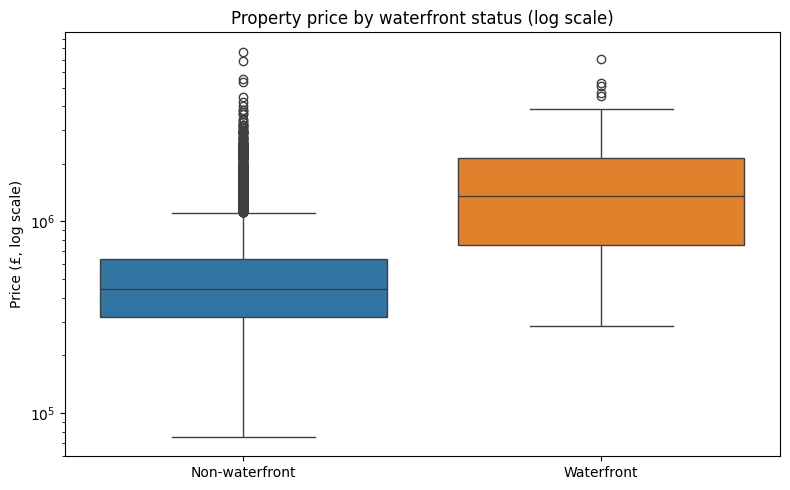

In [17]:
# Price boxplot by waterfront status
# log scale, otherwise the non-waterfront box is squashed flat
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="waterfront_label", y="price", hue="waterfront_label",
            legend=False)
plt.yscale("log")
plt.title("Property price by waterfront status (log scale)")
plt.xlabel("")
plt.ylabel("Price (£, log scale)")
plt.tight_layout()
plt.show()

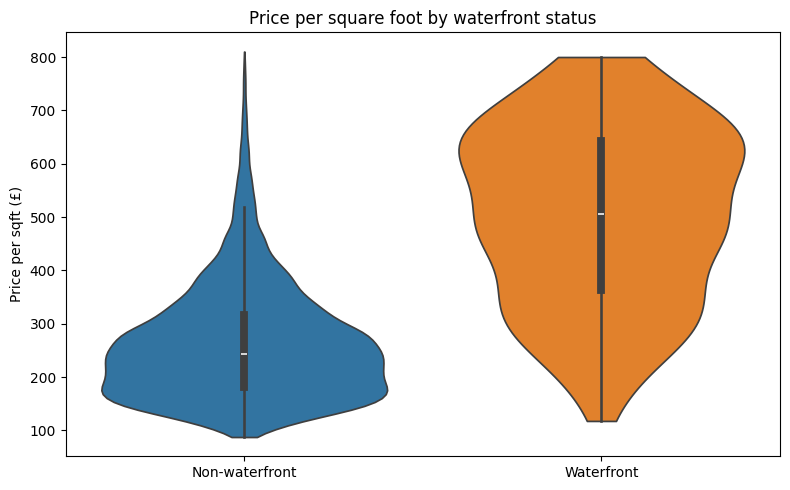

In [18]:
# price per sqft takes house size out of the comparison
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="waterfront_label", y="price_per_sqft", hue="waterfront_label",
               legend=False, cut=0)
plt.title("Price per square foot by waterfront status")
plt.xlabel("")
plt.ylabel("Price per sqft (£)")
plt.tight_layout()
plt.show()

In [19]:
# % of each group in each view rating
view_ct = pd.crosstab(df["waterfront_label"], df["view"], normalize="index") * 100
view_ct.round(1)

view,0,1,2,3,4
waterfront_label,,,,,
Non-waterfront,90.6,1.6,4.6,2.3,0.9
Waterfront,0.0,0.6,5.0,11.9,82.4


Only 159 of all of the houses in the data set (0.8%) were waterfront. Their median price was about three times the median price of non-waterfront homes. The results from the Mann-Whitney test showed that it was extremely unlikely that this difference happened by chance. Initially, I believed that the higher price might just be because waterfront homes are larger, which they are (2,830 vs 1,890 sqft). Therefore, I created a price per square foot graph. As you can see in the graph above, even after taking size out, waterfront homes are approximately two times more expensive per square foot. In addition, 82% of those homes had the highest "view" rating; therefore, at least some portion of the difference in prices may have been due to the view.

## Section 8 - Investigation 2: Floor space

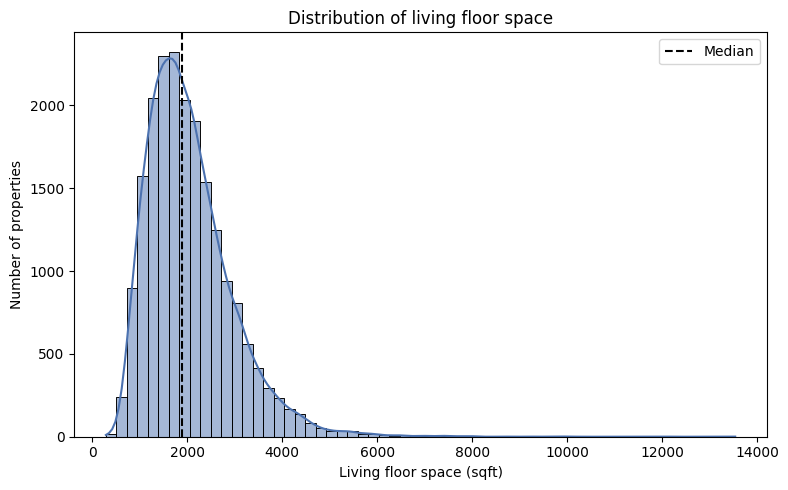

In [20]:
# Floor space distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["sqft_living"], bins=60, kde=True, color="#4C72B0")
plt.axvline(df["sqft_living"].median(), color="black", ls="--", label="Median")
plt.title("Distribution of living floor space")
plt.xlabel("Living floor space (sqft)")
plt.ylabel("Number of properties")
plt.legend()
plt.tight_layout()
plt.show()

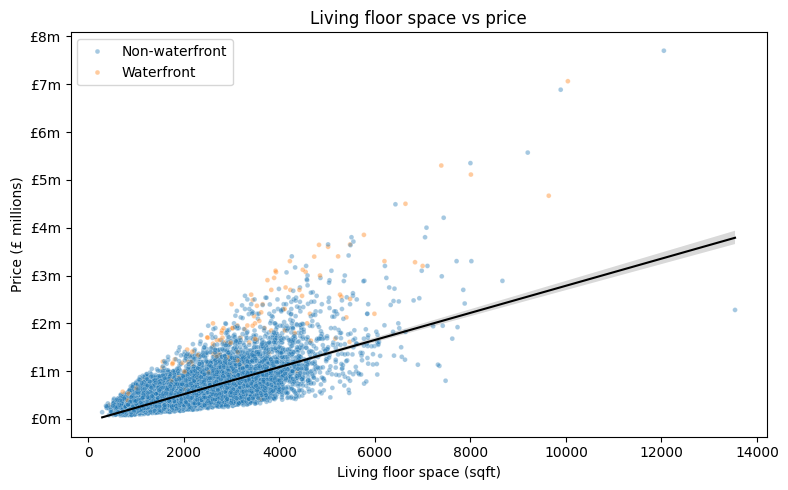

In [21]:
# Floor space vs price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="sqft_living", y="price", hue="waterfront_label",
                alpha=0.4, s=12)
sns.regplot(data=df, x="sqft_living", y="price", scatter=False, color="black",
            line_kws={"lw": 1.5, "label": "Linear trend"})
plt.title("Living floor space vs price")
plt.xlabel("Living floor space (sqft)")
plt.ylabel("Price (£ millions)")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"£{v / 1e6:.0f}m"))
plt.legend(title="")
plt.tight_layout()
plt.show()

In [22]:
# Pearson and Spearman correlation with price
rows = []
for col in ["sqft_living", "living_area", "sqft_total"]:
    pr, pp = stats.pearsonr(df[col], df["price"])
    sr, sp = stats.spearmanr(df[col], df["price"])
    rows.append({"variable": col, "pearson_r": pr, "pearson_p": pp,
                 "spearman_rho": sr, "spearman_p": sp})
space_corr = pd.DataFrame(rows).set_index("variable")
space_corr.style.format({"pearson_r": "{:.3f}", "spearman_rho": "{:.3f}",
                         "pearson_p": "{:.1e}", "spearman_p": "{:.1e}"})

,pearson_r,pearson_p,spearman_rho,spearman_p
variable,,,,
sqft_living,0.701,0.0e+00,0.642,0.0e+00
living_area,0.596,0.0e+00,0.579,0.0e+00
sqft_total,0.086,5.1e-34,0.073,3.8e-25


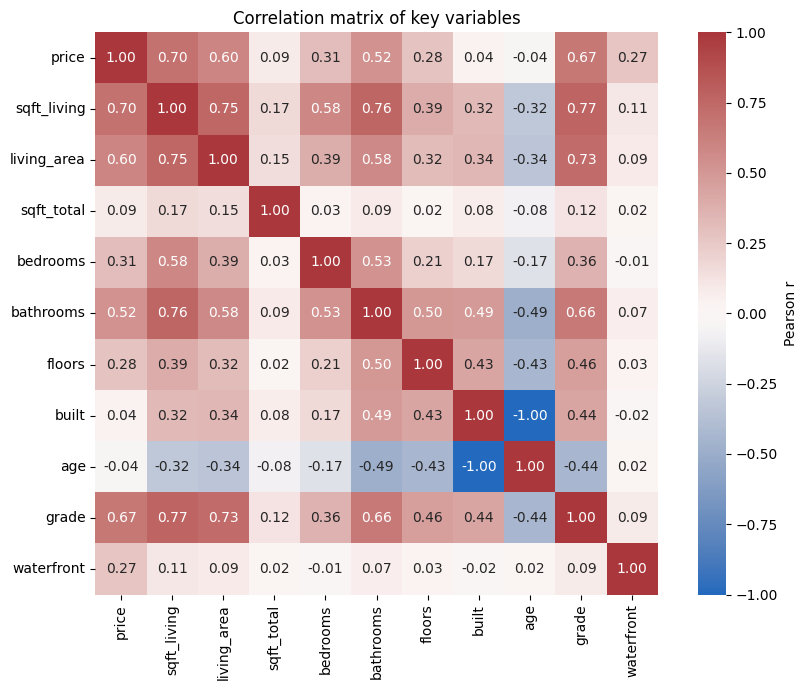

In [23]:
# Correlation heatmap
num_cols = ["price", "sqft_living", "living_area", "sqft_total", "bedrooms",
            "bathrooms", "floors", "built", "age"]
heat_data = df[num_cols].copy()
heat_data["grade"] = df["grade"].astype(int)
heat_data["waterfront"] = df["waterfront"].astype(int)
corr = heat_data.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True,
            cbar_kws={"label": "Pearson r"})
plt.title("Correlation matrix of key variables")
plt.tight_layout()
plt.show()


Living floor space (sqft_living) has a strong correlation to price (r = 0.70), and living_area a moderate one (r = 0.60). Total plot size (sqft_total) had very little correlation (r = 0.09). Buyers seem to be paying for the interior living space rather than the outdoor land. In addition, the data was skewed and prices spread out a lot as house sizes increased, which is why I chose to use Spearman in conjunction with Pearson's r. Upon reviewing my heatmap I saw that grade and number of bathrooms were also highly correlated with both size and price. This means it cannot be said that the size of the home alone caused the price.

## Section 9 - Investigation 3: Is year built correlated with price?

In [24]:
pr, pp = stats.pearsonr(df["built"], df["price"])
sr, sp = stats.spearmanr(df["built"], df["price"])
print(f"Pearson r = {pr:.3f} (p = {pp:.1e});  Spearman rho = {sr:.3f} (p = {sp:.1e})")

Pearson r = 0.040 (p = 1.2e-08);  Spearman rho = 0.081 (p = 8.8e-31)


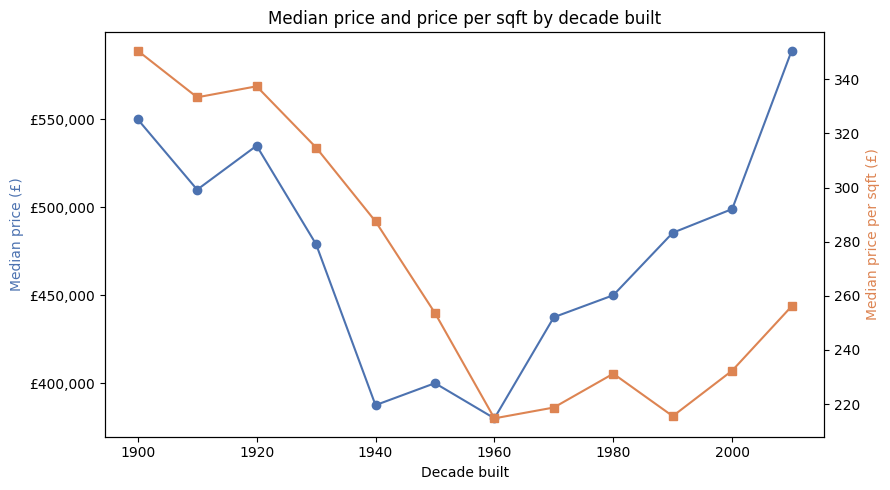

,median_price,median_sqft,n,median_price_per_sqft
decade_built,,,,
1900,550000.0,1610.0,645,350.543478
1910,510000.0,1590.0,805,333.333333
1920,535000.0,1630.0,1189,337.398374
1930,479000.0,1640.0,526,314.793771
1940,387500.0,1370.0,1759,287.500000
1950,400000.0,1630.0,2450,253.658609
1960,380000.0,1835.0,2654,214.754345
1970,437500.0,2040.0,2280,218.755062
1980,450000.0,2060.0,2279,231.250000


In [25]:
# group by decade because a scatter of 20,000 points is too messy
decade = df.groupby("decade_built").agg(median_price=("price", "median"),
                                        median_sqft=("sqft_living", "median"),
                                        n=("price", "size"))
decade["median_price_per_sqft"] = df.groupby("decade_built")["price_per_sqft"].median()

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(decade.index, decade["median_price"], marker="o", color="#4C72B0", label="Median price")
ax1.set_xlabel("Decade built")
ax1.set_ylabel("Median price (£)", color="#4C72B0")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"£{v:,.0f}"))
ax2 = ax1.twinx()
ax2.plot(decade.index, decade["median_price_per_sqft"], marker="s", color="#DD8452",
         label="Median price per sqft")
ax2.set_ylabel("Median price per sqft (£)", color="#DD8452")
ax2.grid(False)
plt.title("Median price and price per sqft by decade built")
plt.tight_layout()
plt.show()
decade

In [26]:
# partial correlation: removes the effect of size, as newer houses are bigger
def residuals(y, x):
    slope, intercept = np.polyfit(x, y, 1)
    return y - (slope * x + intercept)

r_partial, p_partial = stats.pearsonr(residuals(df["price"], df["sqft_living"]),
                                      residuals(df["built"], df["sqft_living"]))
print(f"Partial r (built, price | sqft_living) = {r_partial:.3f}, p = {p_partial:.1e}")

Partial r (built, price | sqft_living) = -0.275, p = 0.0e+00


In [27]:
# Renovated vs never renovated
reno = df.groupby("is_renovated")["price"].agg(["size", "median"])
reno.index = ["Never renovated", "Renovated"]
reno

,size,median
Never renovated,19088,442536.5
Renovated,909,601000.0


To be honest this was probably my favourite part of this project. As it turned out, the correlation between the year of construction and price was very close to zero (r = 0.04). It seemed that there really isn't an obvious link between how old a home is and its value. However, the graph showing all homes by decade shows a U-shape: homes built before 1930 and after 2000 have higher values than those built between 1940 and 1969. After removing the effect of floor area using a partial correlation, the results show a moderate negative correlation (r = −0.28) between the year built and the price; therefore, for similar floor areas, older homes are worth more money. Finally, renovated homes had a much higher median price (£601,000 vs £442,537).

## Section 10 - Additional insights (beyond the brief)
While working on the three questions I noticed some other patterns in the data that could be useful for the company, so I checked them properly here.

In [28]:
# Insight 1: bedrooms vs price
# only houses of similar size (1,800-2,200 sqft) so the comparison is fair
similar_size = df[(df["sqft_living"] >= 1800) & (df["sqft_living"] <= 2200)]
bed_table = similar_size.groupby("bedrooms").agg(homes=("price", "size"),
                                                  median_price=("price", "median"))
# at least 20 houses per group so the medians are reliable
bed_table = bed_table[bed_table["homes"] >= 20]

rho, p_bed = stats.spearmanr(similar_size["bedrooms"], similar_size["price"])
print(f"Spearman rho (bedrooms vs price, similar size) = {rho:.3f}, p = {p_bed:.1e}")
bed_table

Spearman rho (bedrooms vs price, similar size) = -0.105, p = 6.3e-11


,homes,median_price
bedrooms,,
2,170,527475.0
3,1920,450000.0
4,1522,420000.0
5,227,435000.0
6,24,332500.0


In [29]:
# Insight 2: renovation uplift by age group
df["age_group"] = pd.cut(df["built"], bins=[1899, 1939, 1969, 2015],
                         labels=["Before 1940", "1940-1969", "1970 onwards"])
reno_age = df.pivot_table(index="age_group", columns="is_renovated", values="price",
                          aggfunc="median", observed=True)
reno_age.columns = ["Never renovated", "Renovated"]
reno_age["uplift_%"] = 100 * (reno_age["Renovated"] / reno_age["Never renovated"] - 1)
reno_age["renovated_homes"] = df[df["is_renovated"]].groupby("age_group", observed=True).size()
reno_age

,Never renovated,Renovated,uplift_%,renovated_homes
age_group,,,,
Before 1940,520000.0,620000.0,19.230769,422
1940-1969,380000.0,580000.0,52.631579,403
1970 onwards,470950.0,681500.0,44.707506,84


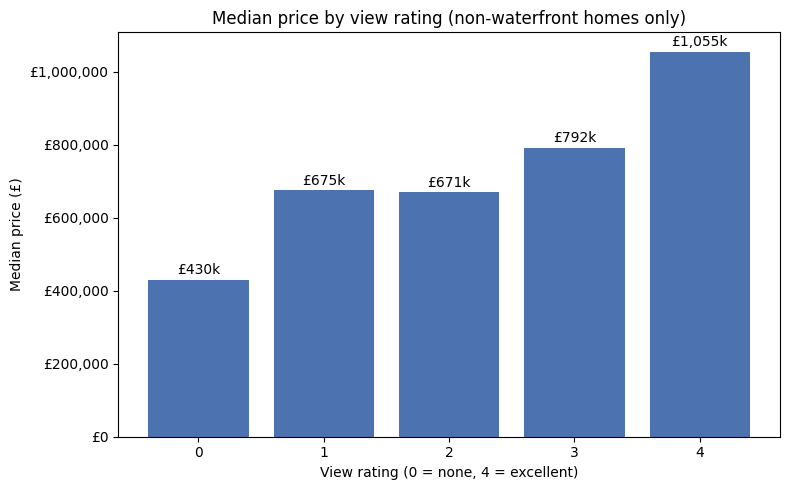

,homes,median_price,median_price_per_sqft
view,,,
0,17972,429900.0,238.972930
1,316,675000.0,296.209184
2,910,670625.0,285.590707
3,462,792500.0,298.368039
4,178,1055400.0,356.607841


In [30]:
# Insight 3: view premium without waterfront
# waterfront homes removed so water can't explain the price
no_water = df[~df["waterfront"]]
view_table = no_water.groupby("view", observed=True).agg(
    homes=("price", "size"),
    median_price=("price", "median"),
    median_price_per_sqft=("price_per_sqft", "median"))

plt.figure(figsize=(8, 5))
plt.bar(view_table.index.astype(str), view_table["median_price"], color="#4C72B0")
for i, v in enumerate(view_table["median_price"]):
    plt.text(i, v + 15000, f"£{v / 1000:,.0f}k", ha="center")
plt.title("Median price by view rating (non-waterfront homes only)")
plt.xlabel("View rating (0 = none, 4 = excellent)")
plt.ylabel("Median price (£)")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"£{v:,.0f}"))
plt.tight_layout()
plt.show()
view_table

In [31]:
# Insight 4: building age bands
df["age_band"] = pd.cut(df["age"], bins=[-1, 10, 25, 50, 75, 115],
                        labels=["0-10", "11-25", "26-50", "51-75", "76+"])
age_table = df.groupby("age_band", observed=True).agg(
    homes=("price", "size"),
    median_price=("price", "median"),
    median_sqft=("sqft_living", "median"),
    median_price_per_sqft=("price_per_sqft", "median"))
age_table

,homes,median_price,median_sqft,median_price_per_sqft
age_band,,,,
0-10,1632,510000.0,2300.0,247.994638
11-25,3778,497000.0,2372.5,218.254138
26-50,6006,427250.0,1990.0,222.500564
51-75,5416,395000.0,1590.0,254.950980
76+,3165,528000.0,1620.0,335.000000


The results above were not part of the brief; however, I believe these would be the most relevant to the business. The bedroom result surprised me, as it suggested that when houses of the same size are compared, more bedrooms generally means a lower price, indicating that buyers tend to value larger rooms rather than additional rooms. The renovation result indicated that properties built between 1940 and 1969 benefit the most from renovation (approximately 53%); this is consistent with them being the cheapest group in Section 9 and indicates a potential buy-and-renovate opportunity. The view result revealed to me that at least a portion of the waterfront premium can be attributed to the view itself, as non-waterfront properties with excellent views sell for approximately 2.5 times more than those without a view. The age bands also indicate that homes over 75 years old are the smallest in terms of floor space but have the highest price per sqft (£335), suggesting that older homes have some type of character premium. These are simply associations and not proof of cause, as grade and other features will also vary across each group.

## Section 11 - Summary of key results

In [32]:
summary = pd.DataFrame({
    "Result": [
        f"Waterfront homes: {int(wf_summary.loc['Waterfront', 'count'])} "
        f"({wf_summary.loc['Waterfront', 'share_%']:.1f}% of stock)",
        f"Waterfront median premium: {100 * premium / med['Non-waterfront']:.0f}%",
        f"sqft_living vs price: Pearson r = {space_corr.loc['sqft_living', 'pearson_r']:.3f}",
        f"sqft_total vs price: Pearson r = {space_corr.loc['sqft_total', 'pearson_r']:.3f}",
        f"built vs price: Pearson r = {pr:.3f}, Spearman rho = {sr:.3f}",
        f"built vs price controlling for size: partial r = {r_partial:.3f}",
    ]})
summary

,Result
0,Waterfront homes: 159 (0.8% of stock)
1,Waterfront median premium: 206%
2,sqft_living vs price: Pearson r = 0.701
3,sqft_total vs price: Pearson r = 0.086
4,"built vs price: Pearson r = 0.040, Spearman rh..."
5,built vs price controlling for size: partial r...


Overall, the size of a house (living floor space) and whether or not the home is on the waterfront appear to be the two strongest predictors of price. Year built only seems to have an effect on house price once you control for size. Looking back at this project, if possible I would like to know where each of these houses is located and when they were sold, so that I could add both location and time of sale into my analysis.